# 03 · Como o tráfego varia no tempo?  🟡 *médio*

Até aqui contamos **quem** aparece. Agora olhamos **quando**. Séries temporais revelam coisas que contagens
totais escondem: picos de ataques, falhas de coleta, ciclos diários, campanhas que começam num dia específico.

**Perguntas deste notebook**

1. Como é a série **por hora** de cada sensor? Há picos ou buracos?
2. Os sensores **sobem e descem juntos**? (correlação) — e o que infla essa correlação?
3. Existe **ciclo diário**? Em que **fuso** faz sentido olhar?
4. A cada dia aparecem **origens novas** ou são sempre as mesmas?
5. Alguma **porta** "acordou" de repente?

**Ferramentas:** `resample`/`floor`, `reindex` para completar o tempo, correlação, z-score robusto.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A pasta raiz da série (onde estão os .py). Funciona tanto na raiz quanto em solucoes/.
RAIZ = os.path.abspath("..") if os.path.basename(os.getcwd()) == "solucoes" else os.getcwd()
sys.path.insert(0, RAIZ)
import holoscope_io as hio
import holoscope_ana as ha
ha.estilo()

# >>> Para usar os DADOS REAIS, troque só esta linha pela pasta dos parquet <<<
PASTA = os.path.join(RAIZ, "dados_sinteticos")
if not os.path.isdir(PASTA):   # primeira vez: gera os dados fictícios (~20 s)
    import subprocess
    subprocess.run([sys.executable, os.path.join(RAIZ, "gerar_sintetico_real.py"), "--saida", PASTA], check=True)

In [2]:
df = hio.carregar_holoscope(PASTA, extras=("geo",))
df["flags"] = hio.flags_texto(df["tcp_flags"])
df["backscatter"] = df["flags"].isin(["SA", "R", "RA"])
df["hora"] = df["ts"].dt.floor("h")
df["dia"] = df["ts"].dt.floor("D")
SENS = sorted(df["sensor"].unique())
COR = ha.cores(SENS)
HORAS = pd.date_range(df["hora"].min(), df["hora"].max(), freq="h")   # eixo de tempo COMPLETO

83 arquivos | 6 sensores (worker) | 2026-09-01 a 2026-09-14 | 2,024,894 pacotes | 87 MB na memória
origens reservadas/privadas descartadas: 35,000


## 1. Série por hora de cada sensor

Passo importante: depois de contar por hora, fazemos `reindex(HORAS)` para que **toda hora** apareça.
Horas sem nenhum pacote viram `NaN` — e **num sensor de darknet, uma hora inteira sem nenhum pacote quase
certamente é falha de coleta**, não silêncio da internet.

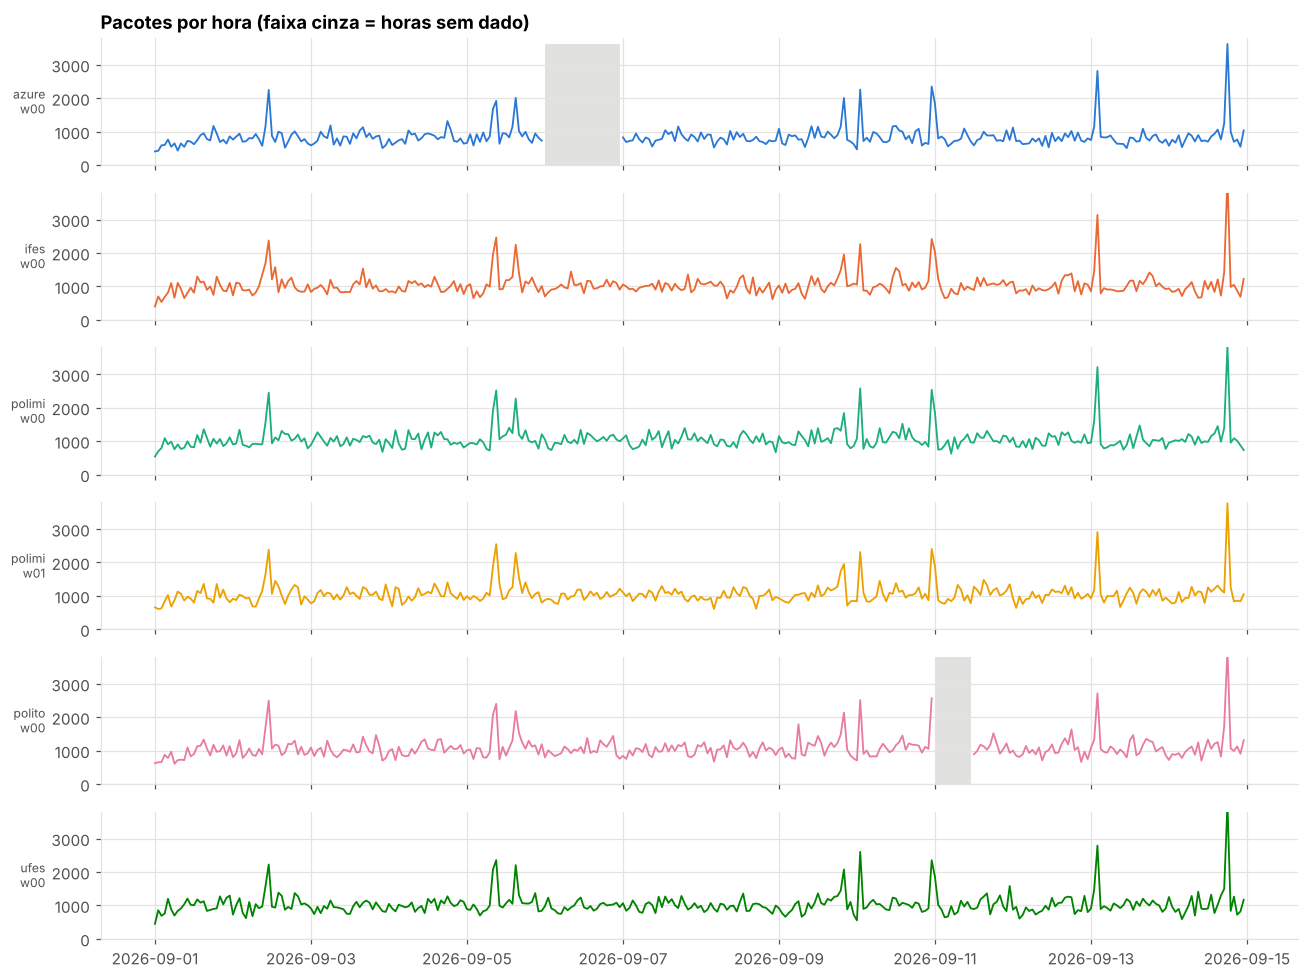

In [3]:
serie = df.groupby(["hora", "sensor"], observed=True).size().unstack().reindex(HORAS)

fig, axs = plt.subplots(len(SENS), 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, s in zip(axs, SENS):
    ax.plot(serie.index, serie[s], color=COR[s], lw=1.2)
    falta = serie[s].isna()
    ax.fill_between(serie.index, 0, serie[s].max(), where=falta, color=ha.CINZA, alpha=0.25, lw=0)
    ax.set_ylabel(s.replace("-worker-", "\nw"), rotation=0, ha="right", va="center", fontsize=8)
    ax.set_ylim(bottom=0)
axs[0].set_title("Pacotes por hora (faixa cinza = horas sem dado)")
plt.tight_layout(); plt.show()

**Leitura:**

* faixas **cinza** = horas sem dados: o dia inteiro que falta no `azure` e a **meia jornada** do `polito`
  (a queda "misteriosa" do notebook 01 se explica: 12 horas de coleta perdidas);
* **picos estreitos e altos** aparecem **ao mesmo tempo em todos os sensores**. Quem consegue atingir todos os
  sensores simultaneamente com tanta intensidade? Vamos separar o backscatter:

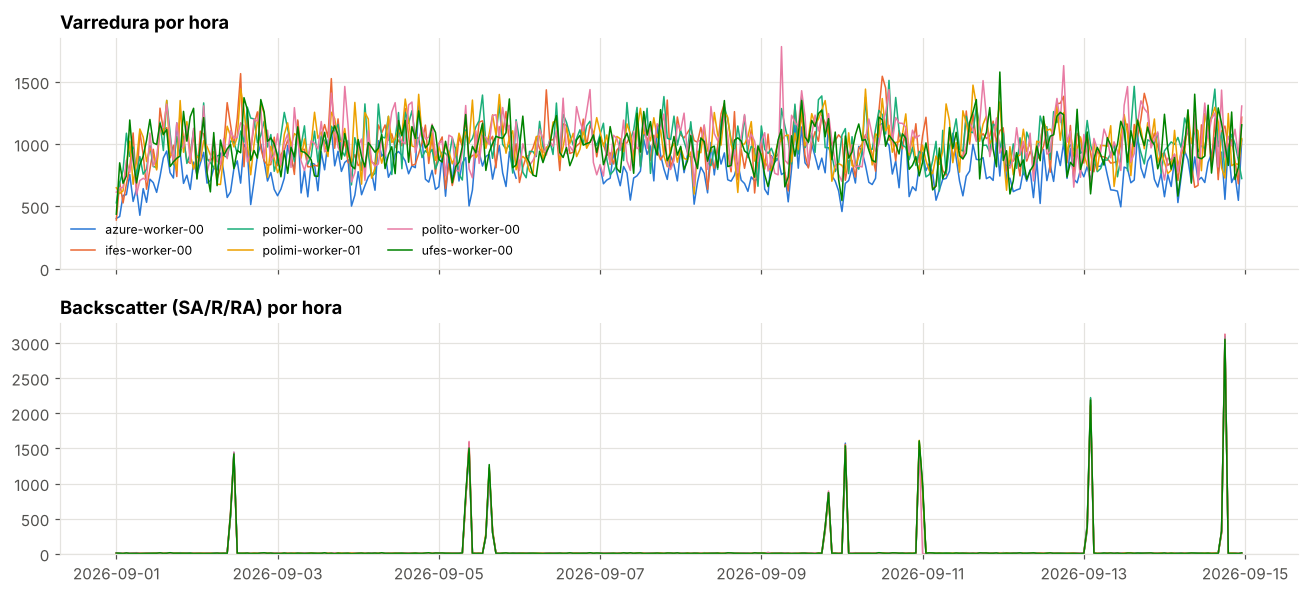

In [4]:
bs = df[df["backscatter"]].groupby(["hora", "sensor"], observed=True).size().unstack().reindex(HORAS).fillna(0)
sc = df[~df["backscatter"]].groupby(["hora", "sensor"], observed=True).size().unstack().reindex(HORAS)

fig, axs = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
for s in SENS:
    axs[0].plot(sc.index, sc[s], color=COR[s], lw=1, label=s)
    axs[1].plot(bs.index, bs[s], color=COR[s], lw=1)
axs[0].set_title("Varredura por hora"); axs[1].set_title("Backscatter (SA/R/RA) por hora")
axs[0].legend(ncol=3, fontsize=8, loc="lower left")
for a in axs: a.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

Os picos são **backscatter**: durante um ataque DDoS com endereços de origem **forjados aleatoriamente**, a vítima
responde para endereços espalhados pela internet inteira — e todos os sensores recebem uma fatia proporcional
ao seu tamanho, **ao mesmo tempo**. (No notebook 06 estimamos a intensidade desses ataques.)

## 2. Os sensores sobem e descem juntos?

A **correlação de Pearson** entre duas séries mede se elas variam juntas (−1 a 1). Vamos calcular entre as séries
horárias dos sensores, **com** e **sem** backscatter.

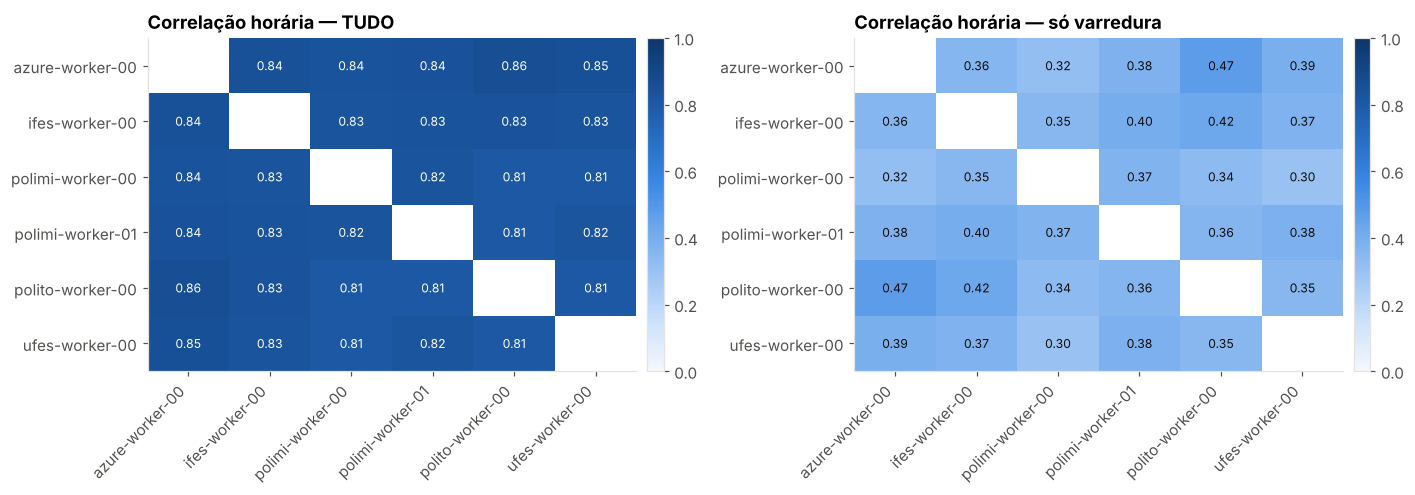

In [5]:
tot = serie.copy()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
ha.heatmap(ha.sem_diagonal(tot.corr()), ax=axs[0], vmin=0, vmax=1, titulo="Correlação horária — TUDO")
ha.heatmap(ha.sem_diagonal(sc.corr()), ax=axs[1], vmin=0, vmax=1, titulo="Correlação horária — só varredura")
plt.tight_layout(); plt.show()

**Leitura:** com backscatter, as correlações ficam **altas** — mas é por causa de **poucos picos** enormes e
simultâneos. Sem eles, a correlação cai bastante: hora a hora, a varredura de fundo varia quase como ruído.

> ⚠️ **Armadilha:** correlação de Pearson é **sensível a extremos**. Poucos eventos podem fabricar uma correlação
> alta. Tente a de **Spearman** (`.corr(method="spearman")`), que usa postos e é mais robusta.

### ✏️ TODO 1 — IPs únicos por dia

Monte em `resp_1` uma tabela **dia × sensor** com o número de **IPs de origem distintos de varredura**
(sem backscatter), com **todos** os dias do período (dia sem dado = `NaN`). Faça um gráfico de linhas.

<details><summary><b>Dica</b> (clique)</summary>

`df[~df["backscatter"]].groupby(["dia", "sensor"], observed=True)["src_ip"].nunique().unstack()`
e depois `.reindex(pd.date_range(..., freq="D", tz="UTC"))`.

</details>

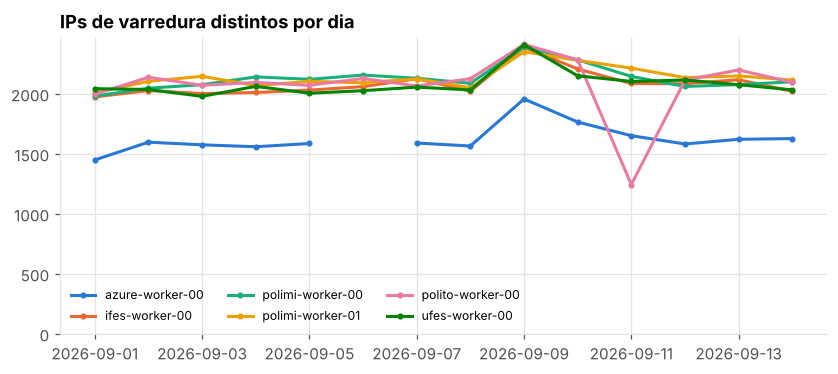

In [6]:
# SOLUÇÃO
DIAS = pd.date_range(df["dia"].min(), df["dia"].max(), freq="D")
resp_1 = (df[~df["backscatter"]].groupby(["dia", "sensor"], observed=True)["src_ip"].nunique()
          .unstack().reindex(DIAS))
fig, ax = plt.subplots(figsize=(9, 3.5))
for s in SENS:
    ax.plot(resp_1.index, resp_1[s], marker="o", ms=3, color=COR[s], label=s)
ax.set_ylim(bottom=0); ax.set_title("IPs de varredura distintos por dia"); ax.legend(ncol=3, fontsize=8)
plt.show()

In [7]:
# Verificação (não precisa mexer)
if resp_1 is None:
    print("⏳ TODO 1 ainda não resolvido")
else:
    assert resp_1.shape == (14, len(SENS)), f"esperava 14 dias x {len(SENS)} sensores, veio {resp_1.shape}"
    assert resp_1["azure-worker-00"].isna().sum() == 1, "o dia sem arquivo do azure deveria ser NaN"
    print("✅ TODO 1 ok")

✅ TODO 1 ok


## 3. Ciclo diário — e o problema do fuso horário

Tráfego gerado por **pessoas** (ou por máquinas ligadas por pessoas) tende a ter **ciclo diário**. Mas em que
fuso? O sensor está num fuso, o atacante em outro, e o `ts` está em **UTC**.

Primeiro, o perfil médio por **hora UTC**, normalizado (1 = média do sensor):

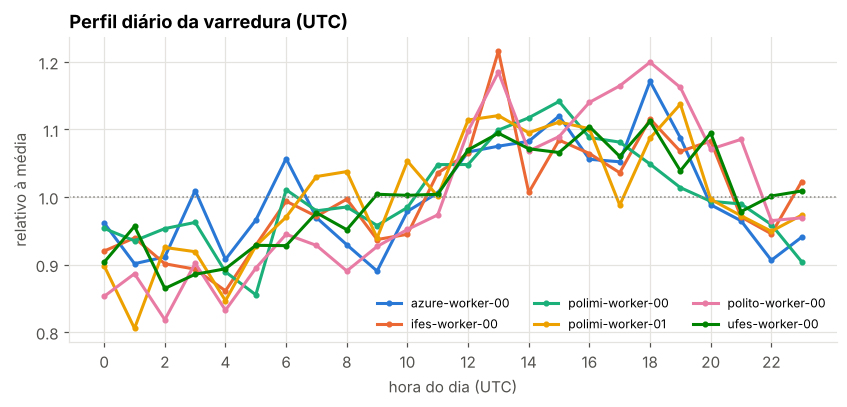

In [8]:
s2 = df[~df["backscatter"]].copy()
s2["hora_utc"] = s2["ts"].dt.hour
perfil = s2.groupby(["hora_utc", "sensor"], observed=True).size().unstack()
perfil = perfil / perfil.mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
for s in SENS:
    ax.plot(perfil.index, perfil[s], color=COR[s], label=s, marker="o", ms=3)
ax.axhline(1, color=ha.CINZA, lw=1, ls=":")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hora do dia (UTC)"); ax.set_ylabel("relativo à média")
ax.set_title("Perfil diário da varredura (UTC)"); ax.legend(ncol=3, fontsize=8)
plt.show()

A variação é moderada (uns ±20% em torno da média): boa parte da varredura "profissional" roda 24 h, mas
algo puxa o tráfego para cima à tarde/noite (UTC). Um suspeito: as **botnets** de dispositivos domésticos
(roteadores, câmeras)? Esses aparelhos são ligados/desligados por pessoas, então o ciclo deveria seguir a
**hora local da origem**, não do sensor nem UTC.

Ideia: aproximar o fuso da origem pela **longitude** (`lon / 15` horas) e comparar o perfil do **Telnet**
(portas 23/2323, alvo clássico da botnet Mirai) em UTC × hora local da origem.

### ✏️ TODO 2 — Telnet: hora UTC × hora local da origem

Para os pacotes de varredura nas portas **23 e 2323**:

1. crie a coluna `hora_local = (hora_utc + round(lon / 15)) % 24`;
2. calcule os dois perfis (UTC e local), normalizados pela média, e desenhe-os no mesmo gráfico;
3. guarde em `resp_2 = (pico_utc, pico_local)` a **hora de pico** de cada perfil.

Qual perfil tem o ciclo mais nítido? Em que hora local é o pico — isso faz sentido para aparelhos domésticos?

<details><summary><b>Dica</b> (clique)</summary>

`np.round(t["lon"] / 15).astype(int)`; o pico é `perfil.idxmax()`.

</details>

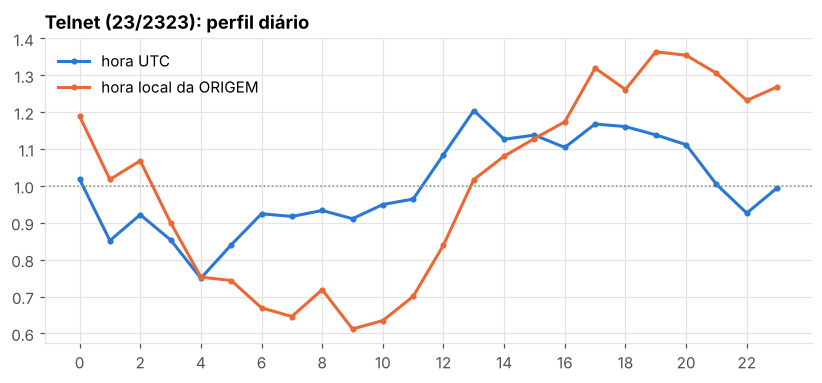

(13, 19)

In [9]:
# SOLUÇÃO
t = s2[s2["dst_port"].isin([23, 2323])].dropna(subset=["lon"]).copy()
t["hora_local"] = (t["hora_utc"] + np.round(t["lon"] / 15).astype(int)) % 24
p_utc = t["hora_utc"].value_counts().sort_index(); p_utc /= p_utc.mean()
p_loc = t["hora_local"].value_counts().sort_index(); p_loc /= p_loc.mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(p_utc.index, p_utc.values, marker="o", ms=3, label="hora UTC", color=ha.PALETA[0])
ax.plot(p_loc.index, p_loc.values, marker="o", ms=3, label="hora local da ORIGEM", color=ha.PALETA[1])
ax.axhline(1, color=ha.CINZA, lw=1, ls=":"); ax.set_xticks(range(0, 24, 2))
ax.set_title("Telnet (23/2323): perfil diário"); ax.legend(); plt.show()
resp_2 = (int(p_utc.idxmax()), int(p_loc.idxmax()))
resp_2

In [10]:
# Verificação (não precisa mexer)
if resp_2 is None:
    print("⏳ TODO 2 ainda não resolvido")
else:
    assert all(0 <= h < 24 for h in resp_2)
    print("✅ TODO 2 ok — pico UTC às", resp_2[0], "h; pico local às", resp_2[1], "h")

✅ TODO 2 ok — pico UTC às 13 h; pico local às 19 h


## 4. Horas anômalas: um detector simples

Como achar **automaticamente** as horas "estranhas"? Um **z-score** mede quantos desvios-padrão um valor está da
média. Mas média e desvio-padrão são estragados pelos próprios picos que queremos achar. A versão **robusta**
usa **mediana** e **MAD** (desvio absoluto mediano):

$$ z_{rob} = \frac{x - \text{mediana}}{1{,}4826 \cdot \text{MAD}} $$

(o 1,4826 faz o MAD ser comparável ao desvio-padrão quando os dados são normais.)

### ✏️ TODO 3 — Detectar horas anômalas

Para cada sensor, calcule o z-score robusto da série **total** por hora (`serie`) e liste em `resp_3` um
`DataFrame` com as horas em que **z > 5** (colunas: `hora`, `sensor`, `pacotes`, `z`). Quantas horas distintas
aparecem? Elas coincidem entre sensores? Coincidem com os picos de backscatter?

<details><summary><b>Dica</b> (clique)</summary>

`med = serie.median()`, `mad = (serie - med).abs().median()`, `z = (serie - med) / (1.4826 * mad)`.
Depois `z.stack()` para formato longo e filtre `> 5`.

</details>

In [11]:
# SOLUÇÃO
med = serie.median()
mad = (serie - med).abs().median()
z = (serie - med) / (1.4826 * mad)
longo = pd.DataFrame({"pacotes": serie.stack(), "z": z.stack()}).reset_index()
longo.columns = ["hora", "sensor", "pacotes", "z"]
resp_3 = longo[longo["z"] > 5].sort_values(["hora", "sensor"]).reset_index(drop=True)
print(resp_3["hora"].nunique(), "horas distintas;",
      f"{resp_3.groupby('hora')['sensor'].nunique().mean():.1f} sensores por hora anômala (média)")
resp_3.groupby("hora").agg(sensores=("sensor", "nunique"), pacotes=("pacotes", "sum"), z_max=("z", "max")).round(1)

10 horas distintas; 5.7 sensores por hora anômala (média)


,sensores,pacotes,z_max
hora,,,
2026-09-02 11:00:00+00:00,6,14172.0,9.7
2026-09-05 08:00:00+00:00,6,11564.0,6.6
2026-09-05 09:00:00+00:00,6,14207.0,9.2
2026-09-05 15:00:00+00:00,6,13202.0,8.2
2026-09-09 20:00:00+00:00,5,10126.0,8.1
2026-09-10 01:00:00+00:00,6,14527.0,9.8
2026-09-10 23:00:00+00:00,6,14625.0,10.4
2026-09-11 00:00:00+00:00,4,7610.0,7.0
2026-09-13 02:00:00+00:00,6,17583.0,13.5


In [12]:
# Verificação (não precisa mexer)
if resp_3 is None:
    print("⏳ TODO 3 ainda não resolvido")
else:
    assert {"hora", "sensor", "pacotes", "z"} <= set(resp_3.columns) and (resp_3["z"] > 5).all()
    assert 0 < resp_3["hora"].nunique() < 200
    print("✅ TODO 3 ok")

✅ TODO 3 ok


## 5. Origens novas a cada dia: a "curva de descoberta"

Se a darknet visse sempre as mesmas origens, o número **acumulado** de IPs distintos pararia de crescer.
Se cada dia trouxesse gente nova, ele cresceria sem parar. Na prática fica no meio.

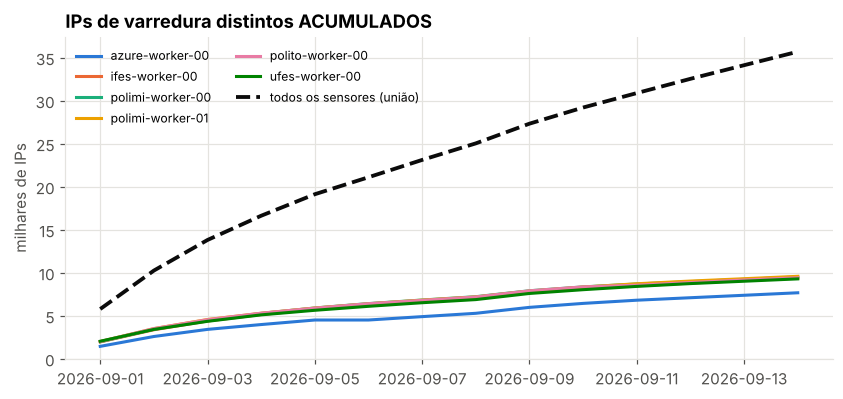

dia,2026-09-01 00:00:00+00:00,2026-09-02 00:00:00+00:00,2026-09-03 00:00:00+00:00,2026-09-04 00:00:00+00:00,2026-09-05 00:00:00+00:00,2026-09-06 00:00:00+00:00,2026-09-07 00:00:00+00:00,2026-09-08 00:00:00+00:00,2026-09-09 00:00:00+00:00,2026-09-10 00:00:00+00:00,2026-09-11 00:00:00+00:00,2026-09-12 00:00:00+00:00,2026-09-13 00:00:00+00:00,2026-09-14 00:00:00+00:00
IPs ativos no dia,5787.0,5952.0,5996.0,5869.0,5938.0,5576.0,5958.0,5903.0,6407.0,6171.0,5874.0,5990.0,6041.0,5880.0
nunca vistos antes,5787.0,4470.0,3557.0,2815.0,2500.0,1973.0,2014.0,1922.0,2289.0,1877.0,1678.0,1658.0,1582.0,1570.0
% novos,100.0,75.1,59.3,48.0,42.1,35.4,33.8,32.6,35.7,30.4,28.6,27.7,26.2,26.7


In [13]:
sc_df = df[~df["backscatter"]]
primeiro_dia = sc_df.groupby(["sensor", "src_ip"], observed=True)["dia"].min()
acum = (primeiro_dia.groupby(level="sensor", observed=True).value_counts().unstack(level=0)
        .sort_index().reindex(pd.date_range(df["dia"].min(), df["dia"].max(), freq="D")).fillna(0).cumsum())
uniao = sc_df.groupby("src_ip")["dia"].min().value_counts().sort_index().cumsum()

fig, ax = plt.subplots(figsize=(9, 3.8))
for s in SENS:
    ax.plot(acum.index, acum[s] / 1000, color=COR[s], label=s)
ax.plot(uniao.index, uniao / 1000, color=ha.TEXTO, lw=2.5, ls="--", label="todos os sensores (união)")
ax.set_ylabel("milhares de IPs"); ax.set_ylim(bottom=0)
ax.set_title("IPs de varredura distintos ACUMULADOS"); ax.legend(ncol=2, fontsize=8)
plt.show()

novos = uniao.diff().fillna(uniao.iloc[0])
ativos = sc_df.groupby("dia")["src_ip"].nunique()
pd.DataFrame({"IPs ativos no dia": ativos, "nunca vistos antes": novos.astype(int),
              "% novos": (novos / ativos * 100).round(1)}).T

**Leitura:** a curva **não satura** em duas semanas — todo dia, uma fração grande dos IPs ativos é **inédita**.
Repare também na tabela: num dia da segunda semana, tanto os IPs ativos quanto os "nunca vistos" sobem de repente
(o mesmo dia do "morro" no gráfico do TODO 1). O que aconteceu? 👇

> ⚠️ **Armadilha (censura):** nos primeiros dias, "nunca visto antes" é inflado porque **não sabemos** o que
> aconteceu antes do início da coleta. Os primeiros dias de qualquer série de "novidade" são enviesados.

## 6. Uma porta que "acordou"

Mapa de calor **porta × dia** com o nº de **IPs distintos**, dividido pelo **máximo da própria porta**
(1 = o dia mais movimentado daquela porta). Assim portas grandes e pequenas ficam na mesma escala.
Entram as portas com pelo menos 300 IPs distintos no período.

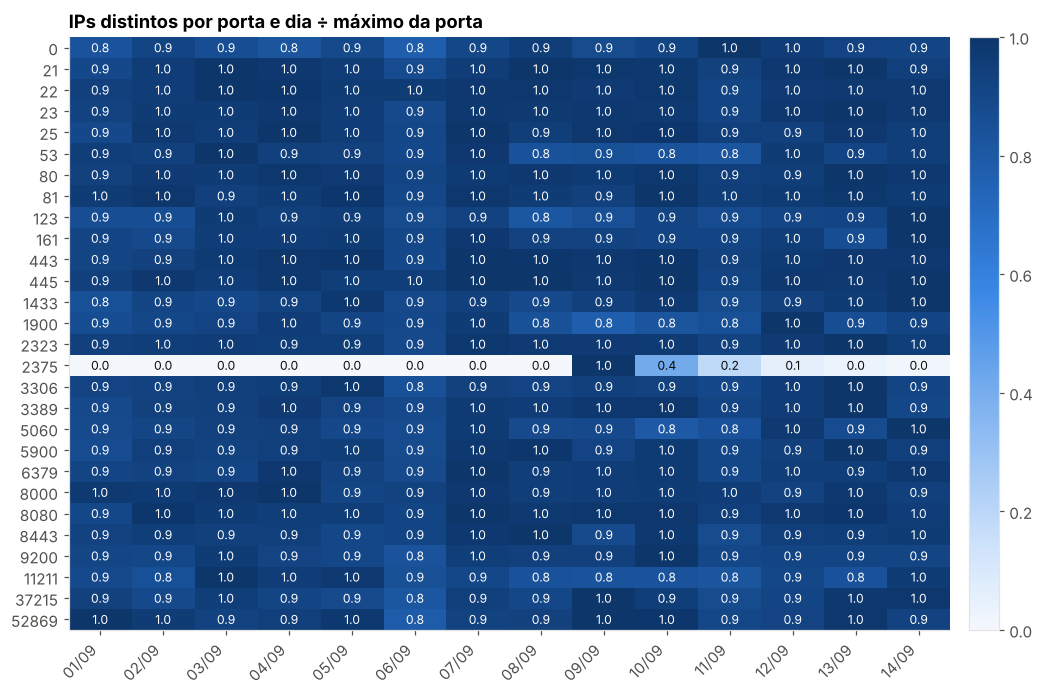

In [14]:
ips_porta = sc_df.groupby(["dst_port", "dia"])["src_ip"].nunique().unstack(fill_value=0)
total_ips = sc_df.groupby("dst_port")["src_ip"].nunique()
portas = total_ips[total_ips >= 300].index.sort_values()
rel = ips_porta.loc[portas]
rel = rel.div(rel.max(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(11, 7))
ha.heatmap(rel.rename(columns=lambda d: d.strftime("%d/%m")), ax=ax, fmt="{:.1f}", vmin=0, vmax=1,
           titulo="IPs distintos por porta e dia ÷ máximo da porta")
plt.show()

**Leitura:** quase todas as linhas são uniformes (portas "de sempre", varridas todo dia). Procure uma linha
**escura de um lado e clara do outro**: uma porta que praticamente não existia e passa a ser varrida por centenas
de origens. Isso é a assinatura de uma **campanha nova** — por exemplo, logo depois da divulgação de uma
vulnerabilidade num serviço.

### ✏️ TODO 4 — Qual porta mais cresceu?

Compare a **primeira** semana (dias 1–7) com a **segunda** (dias 8–14). Para cada porta com pelo menos 50 IPs
no período, calcule a razão `IPs distintos na 2ª semana / (IPs distintos na 1ª semana + 1)` e guarde em `resp_4`
a **porta** com a maior razão. Depois faça a série diária de IPs distintos dessa porta **por sensor**:
o crescimento aparece em todos os sensores ao mesmo tempo?

<details><summary><b>Dica</b> (clique)</summary>

`semana = np.where(sc_df["ts"] < "2026-09-08", 1, 2)`, depois `groupby(["dst_port", semana])["src_ip"].nunique()`.

</details>

dst_port
2375     266.000000
0          1.131274
3389       1.031074
1433       1.030683
37215      1.030153
dtype: float64


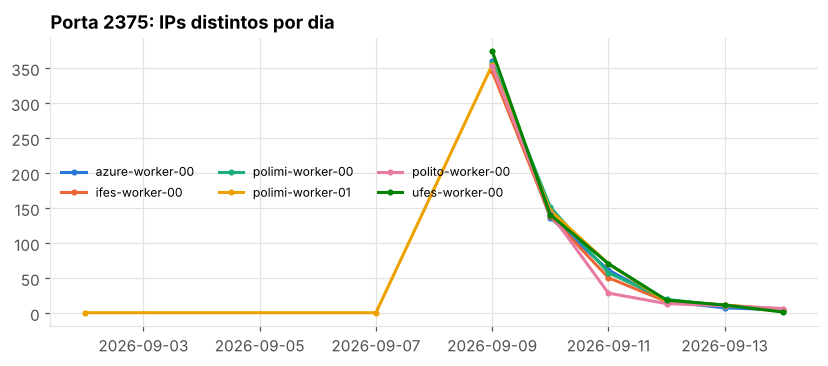

In [15]:
# SOLUÇÃO
semana = np.where(sc_df["ts"] < pd.Timestamp("2026-09-08", tz="UTC"), 1, 2)
w = sc_df.groupby([sc_df["dst_port"], semana])["src_ip"].nunique().unstack(fill_value=0)
w = w[w.sum(axis=1) >= 50]
razao = (w[2] / (w[1] + 1)).sort_values(ascending=False)
resp_4 = int(razao.index[0])
print(razao.head())
d = sc_df[sc_df["dst_port"] == resp_4].groupby(["dia", "sensor"], observed=True)["src_ip"].nunique().unstack()
fig, ax = plt.subplots(figsize=(9, 3.4))
for s in SENS:
    ax.plot(d.index, d[s], marker="o", ms=3, color=COR[s], label=s)
ax.set_title(f"Porta {resp_4}: IPs distintos por dia"); ax.legend(ncol=3, fontsize=8); plt.show()

In [16]:
# Verificação (não precisa mexer)
if resp_4 is None:
    print("⏳ TODO 4 ainda não resolvido")
else:
    assert isinstance(resp_4, (int, np.integer))
    print("✅ TODO 4 ok — porta", resp_4)

✅ TODO 4 ok — porta 2375


## Resumo

* Sempre **complete o eixo de tempo** (`reindex`) e diferencie **sem dado** (`NaN`) de **zero**.
* Picos simultâneos em todos os sensores costumam ser **backscatter** de DDoS.
* Correlação de Pearson é inflada por poucos extremos; use **Spearman** e/ou tire os eventos.
* Ciclos diários de botnets domésticas aparecem na **hora local da origem**, não em UTC.
* **Z-score robusto** (mediana/MAD) é um detector de anomalias simples e eficaz.
* Novas origens aparecem todo dia; campanhas novas aparecem como **portas que acordam**.

## Desafios (sem solução)

1. **Spearman.** Refaça as matrizes de correlação com `method="spearman"`. Quanto muda?
2. **Atraso entre sensores.** Calcule a **correlação cruzada** entre a série de dois sensores com defasagens de
   −3 a +3 horas. O máximo está em 0?
3. **Fim de semana.** Com só duas semanas não dá para concluir muito sobre dia da semana. Quantas semanas você
   precisaria para comparar sábado × terça com alguma confiança? (Pense em quantas observações de cada dia teria.)
4. **Fuso pelo país.** A aproximação `lon / 15` é grosseira (a China inteira usa UTC+8!). Monte um dicionário
   país → fuso oficial e refaça o TODO 2. O pico fica mais nítido?